<a href="https://colab.research.google.com/github/hiba-ben-ali/churn_prediction_telco/blob/main/churn_prediction_telco.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prédiction du churn client (Telco)

## Objectif
Prédire quels clients d'un opérateur télécom vont **résilier leur abonnement** (churn), afin de pouvoir leur proposer une offre de rétention avant leur départ.

## Données
- **Source** : *Telco Customer Churn* (IBM, disponible sur Kaggle), fichier `WA_Fn-UseC_-Telco-Customer-Churn.csv`
- **Taille** : 7 043 clients, 21 colonnes (contrat, services souscrits, facturation, ancienneté, etc.)
- **Cible** : `Churn` (Yes/No), classes déséquilibrées (environ 26 % de départs)

## Méthode
1. Nettoyage (conversion de `TotalCharges`, regroupement des modalités « No internet service »)
2. Analyse exploratoire (contrat, ancienneté, charges mensuelles)
3. Encodage des variables et séparation train/test (80/20, stratifiée)
4. Modèles : **Régression logistique** et **Random Forest**
5. Évaluation avec precision, recall et F1 (l'accuracy seule est trompeuse ici)
6. Ajustement du **seuil de décision** pour améliorer le recall

## Résultats
| Modèle | Seuil | Precision | Recall | F1 |
|---|---|---|---|---|
| Random Forest | 0.5 | 61.2 % | 48.1 % | 53.9 % |
| Régression logistique | 0.5 | 63.6 % | 54.5 % | 58.7 % |
| **Régression logistique** | **0.3** | 52.3 % | **74.1 %** | **61.3 %** |

Le modèle retenu est la régression logistique avec un seuil de 0.3 : il détecte environ 74 % des clients qui vont partir, au prix de plus de fausses alertes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
%matplotlib inline

In [2]:
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Shape:", df.shape)
df.info()

Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 n

In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
pd.to_numeric(df['TotalCharges'], errors='coerce').isna().sum()

np.int64(11)

In [7]:
df[pd.to_numeric(df['TotalCharges'], errors='coerce').isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [8]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['TotalCharges'].isna().sum()
df.dtypes['TotalCharges']

dtype('float64')

In [9]:
print(df['Churn'].value_counts())
print("\n%:")
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

%:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


/tmp/ipykernel_4161/2406348399.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette=['#2ecc71', '#e74c3c'])


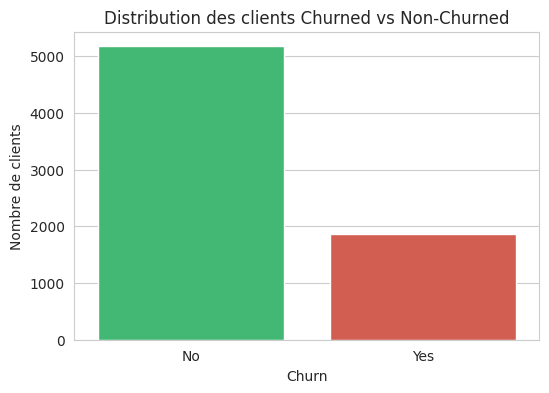

In [10]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', palette=['#2ecc71', '#e74c3c'])
plt.title('Distribution des clients Churned vs Non-Churned')
plt.xlabel('Churn')
plt.ylabel('Nombre de clients')
plt.show()

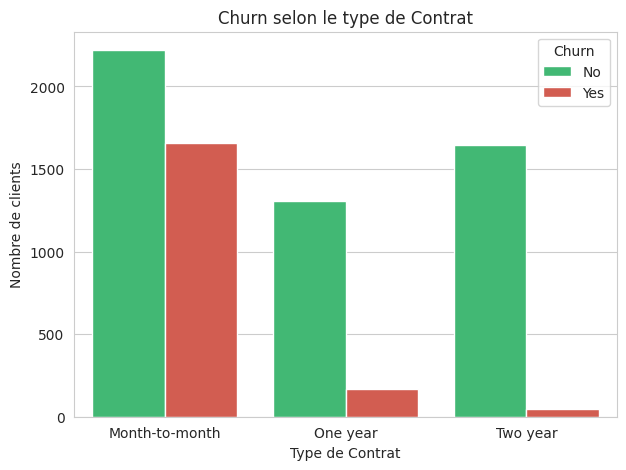

In [11]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x='Contract', hue='Churn', palette=['#2ecc71', '#e74c3c'])
plt.title('Churn selon le type de Contrat')
plt.xlabel('Type de Contrat')
plt.ylabel('Nombre de clients')
plt.show()

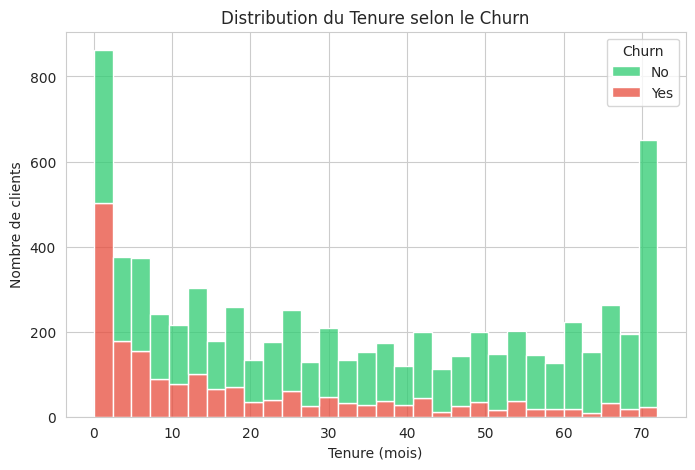

In [12]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, multiple='stack', palette=['#2ecc71', '#e74c3c'])
plt.title('Distribution du Tenure selon le Churn')
plt.xlabel('Tenure (mois)')
plt.ylabel('Nombre de clients')
plt.show()

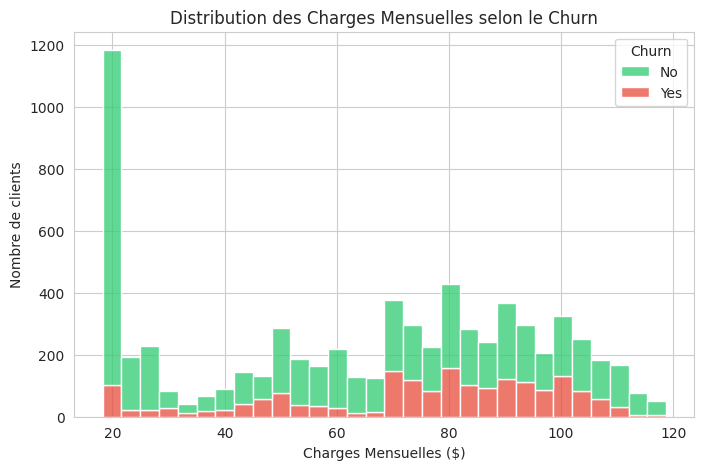

In [13]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', bins=30, multiple='stack', palette=['#2ecc71', '#e74c3c'])
plt.title('Distribution des Charges Mensuelles selon le Churn')
plt.xlabel('Charges Mensuelles ($)')
plt.ylabel('Nombre de clients')
plt.show()

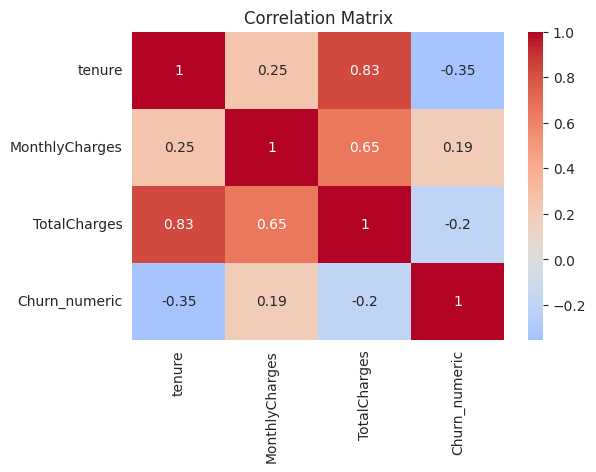

In [14]:

df['Churn_numeric'] = df['Churn'].map({'Yes': 1, 'No': 0})
plt.figure(figsize=(6,4))
corr = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_numeric']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

In [15]:
df_model = df.drop(['customerID'], axis=1)
df_model.shape

(7043, 21)

In [16]:
df_model.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_numeric
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [17]:
df_model = df_model.drop(['Churn'], axis=1)
df_model.columns.tolist()

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn_numeric']

In [18]:
df_model = df_model.drop(['TotalCharges'], axis=1)
df_model.shape

(7043, 19)

In [19]:
for col in df_model.select_dtypes(include='object').columns:
    print(col, ":", df_model[col].unique())

gender : ['Female' 'Male']
Partner : ['Yes' 'No']
Dependents : ['No' 'Yes']
PhoneService : ['No' 'Yes']
MultipleLines : ['No phone service' 'No' 'Yes']
InternetService : ['DSL' 'Fiber optic' 'No']
OnlineSecurity : ['No' 'Yes' 'No internet service']
OnlineBackup : ['Yes' 'No' 'No internet service']
DeviceProtection : ['No' 'Yes' 'No internet service']
TechSupport : ['No' 'Yes' 'No internet service']
StreamingTV : ['No' 'Yes' 'No internet service']
StreamingMovies : ['No' 'Yes' 'No internet service']
Contract : ['Month-to-month' 'One year' 'Two year']
PaperlessBilling : ['Yes' 'No']
PaymentMethod : ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


In [20]:
cols_internet = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                  'TechSupport', 'StreamingTV', 'StreamingMovies']

for col in cols_internet:
    df_model[col] = df_model[col].replace('No internet service', 'No')

df_model['MultipleLines'] = df_model['MultipleLines'].replace('No phone service', 'No')

for col in cols_internet + ['MultipleLines']:
    print(col, ":", df_model[col].unique())

OnlineSecurity : ['No' 'Yes']
OnlineBackup : ['Yes' 'No']
DeviceProtection : ['No' 'Yes']
TechSupport : ['No' 'Yes']
StreamingTV : ['No' 'Yes']
StreamingMovies : ['No' 'Yes']
MultipleLines : ['No' 'Yes']


In [21]:
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling',
               'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
               'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

for col in binary_cols:
    df_model[col] = df_model[col].map({'Yes': 1, 'No': 0})

df_model['gender'] = df_model['gender'].map({'Male': 1, 'Female': 0})

df_model[binary_cols + ['gender']].head()

,Partner,Dependents,PhoneService,PaperlessBilling,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,gender
0,1,0,0,1,0,0,1,0,0,0,0,0
1,0,0,1,0,0,1,0,1,0,0,0,1
2,0,0,1,1,0,1,1,0,0,0,0,1
3,0,0,0,0,0,1,0,1,1,0,0,1
4,0,0,1,1,0,0,0,0,0,0,0,0


In [22]:
df_model = pd.get_dummies(df_model, columns=['InternetService', 'Contract', 'PaymentMethod'], drop_first=True)
df_model.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,PaperlessBilling,MonthlyCharges,Churn_numeric,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,1,29.85,0,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,1,0,1,...,0,56.95,0,False,False,True,False,False,False,True
2,1,0,0,0,2,1,0,1,1,0,...,1,53.85,1,False,False,False,False,False,False,True
3,1,0,0,0,45,0,0,1,0,1,...,0,42.30,0,False,False,True,False,False,False,False
4,0,0,0,0,2,1,0,0,0,0,...,1,70.70,1,True,False,False,False,False,True,False


In [23]:
df_model = df_model.astype(int) if False else df_model
new_cols = [col for col in df_model.columns if 'InternetService_' in col or 'Contract_' in col or 'PaymentMethod_' in col]
df_model[new_cols] = df_model[new_cols].astype(int)

df_model.shape

(7043, 23)

In [24]:
X = df_model.drop('Churn_numeric', axis=1)
y = df_model['Churn_numeric']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 22)
y shape: (7043,)


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (5634, 22)
Test shape: (1409, 22)


In [26]:
from sklearn.linear_model import LogisticRegression
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train , y_train)
print("Model trained!")

Model trained!


In [27]:
y_pred = log_model.predict(X_test)
print("Prédictions:", y_pred[:10])
print("Réalité:    ", y_test[:10].values)

Prédictions: [0 1 0 0 0 1 0 0 0 0]
Réalité:     [0 0 0 0 0 0 0 0 0 1]


In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7963094393186657
Precision: 0.6355140186915887
Recall: 0.5454545454545454
F1-Score: 0.5870503597122302

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.64      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



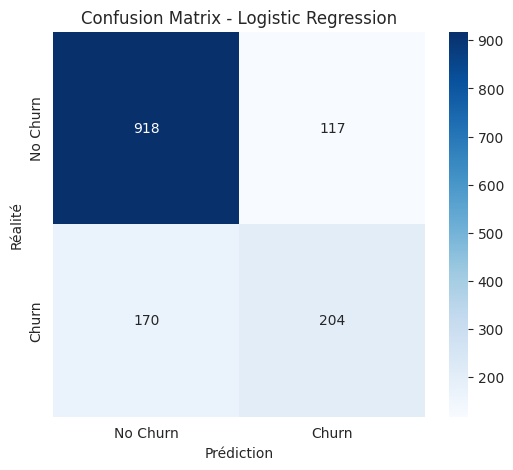

In [29]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.xlabel('Prédiction')
plt.ylabel('Réalité')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [30]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print("Random Forest trained!")

Random Forest trained!


In [31]:
y_pred_rf = rf_model.predict(X_test)

print("=== Random Forest ===")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-Score:", f1_score(y_test, y_pred_rf))

print("\n=== Logistic Regression ===")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

=== Random Forest ===
Accuracy: 0.7814052519517388
Precision: 0.6122448979591837
Recall: 0.48128342245989303
F1-Score: 0.5389221556886228

=== Logistic Regression ===
Accuracy: 0.7963094393186657
Precision: 0.6355140186915887
Recall: 0.5454545454545454
F1-Score: 0.5870503597122302


In [32]:

coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': log_model.coef_[0]
})

coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()
coefficients = coefficients.sort_values('Abs_Coefficient', ascending=False)

print(coefficients.head(10))

                           Feature  Coefficient  Abs_Coefficient
18               Contract_Two year    -1.307954         1.307954
15     InternetService_Fiber optic     1.134817         1.134817
16              InternetService_No    -1.045037         1.045037
17               Contract_One year    -0.683871         0.683871
20  PaymentMethod_Electronic check     0.388827         0.388827
6                    MultipleLines     0.370559         0.370559
13                PaperlessBilling     0.369799         0.369799
11                     StreamingTV     0.368395         0.368395
12                 StreamingMovies     0.367773         0.367773
7                   OnlineSecurity    -0.346768         0.346768


In [33]:
probabilites = log_model.predict_proba(X_test)[:, 1]

seuil = 0.3
y_pred_seuil = (probabilites >= seuil).astype(int)

print("Seuil:", seuil)
print("Precision:", precision_score(y_test, y_pred_seuil))
print("Recall:", recall_score(y_test, y_pred_seuil))
print("F1-Score:", f1_score(y_test, y_pred_seuil))

Seuil: 0.3
Precision: 0.5226415094339623
Recall: 0.7406417112299465
F1-Score: 0.6128318584070797


In [34]:
for seuil in [0.5, 0.4, 0.3, 0.2, 0.1]:
    y_pred_seuil = (probabilites >= seuil).astype(int)
    print("Seuil:", seuil)
    print("  Precision:", round(precision_score(y_test, y_pred_seuil), 3))
    print("  Recall:   ", round(recall_score(y_test, y_pred_seuil), 3))
    print("  F1-Score: ", round(f1_score(y_test, y_pred_seuil), 3))

Seuil: 0.5
  Precision: 0.636
  Recall:    0.545
  F1-Score:  0.587
Seuil: 0.4
  Precision: 0.568
  Recall:    0.66
  F1-Score:  0.611
Seuil: 0.3
  Precision: 0.523
  Recall:    0.741
  F1-Score:  0.613
Seuil: 0.2
  Precision: 0.472
  Recall:    0.856
  F1-Score:  0.608
Seuil: 0.1
  Precision: 0.404
  Recall:    0.947
  F1-Score:  0.566


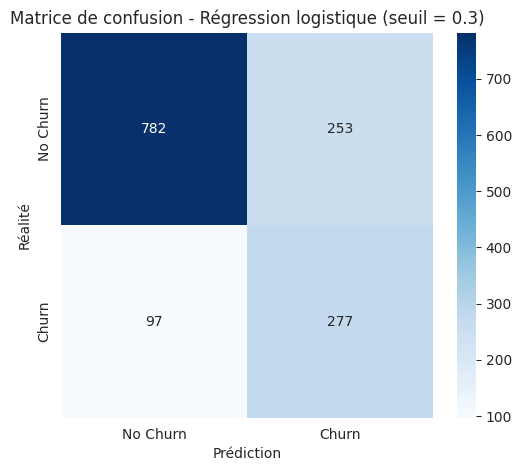

In [35]:
# Matrice de confusion avec le seuil final
seuil_final = 0.3
y_pred_final = (probabilites >= seuil_final).astype(int)

cm_final = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6,5))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.xlabel('Prédiction')
plt.ylabel('Réalité')
plt.title('Matrice de confusion - Régression logistique (seuil = 0.3)')
plt.show()

## Conclusion

- **Modèle retenu** : régression logistique, meilleure que le Random Forest (recall 54.5 % contre 48.1 % au seuil 0.5).
- **Problème** : avec le seuil par défaut (0.5), le modèle rate presque la moitié des clients qui vont partir.
- **Solution** : abaisser le seuil de décision à **0.3**. Le recall passe de 54.5 % à 74.1 %, avec une precision de 52.3 % et le meilleur F1 (61.3 %).
- **Facteurs principaux du churn** : contrat mensuel, fibre optique, paiement par chèque électronique. Les contrats de 1 et 2 ans réduisent fortement le churn.
- **Limite** : le seuil a été choisi en regardant le jeu de test ; une validation croisée serait plus rigoureuse.
- **Choix métier** : le bon seuil dépend du coût d'une offre de rétention par rapport à celui d'un client perdu.